In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/spam.csv", encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "text"]

print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Missing values:\n", df.isnull().sum())
df.head()

Shape: (5572, 2)
Duplicates: 403
Missing values:
 label    0
text     0
dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


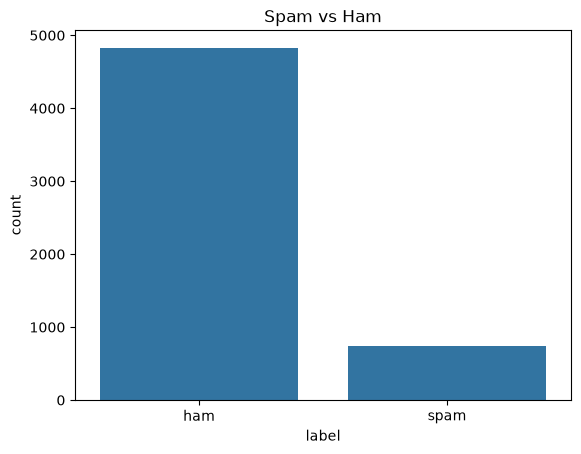

In [2]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

sns.countplot(x="label", data=df)
plt.title("Spam vs Ham")
plt.show()

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
df["length"] = df["text"].apply(len)
df["word_count"] = df["text"].apply(lambda x: len(x.split()))

print("Shape after removing duplicates:", df.shape)
print(df.groupby("label")[["length", "word_count"]].mean().round(1))

Shape after removing duplicates: (5169, 4)
       length  word_count
label                    
ham      70.5        14.1
spam    137.9        23.7


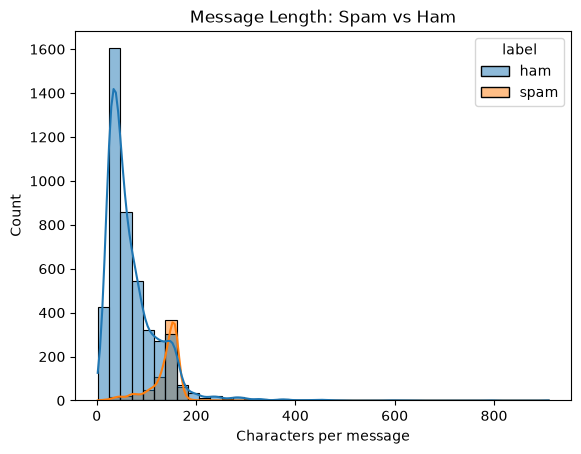

In [4]:
sns.histplot(data=df, x="length", hue="label", bins=40, kde=True)
plt.title("Message Length: Spam vs Ham")
plt.xlabel("Characters per message")
plt.show()

In [5]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

def top_words(label, n=15):
    words = []
    for t in df[df["label"] == label]["text"]:
        words += [w for w in re.findall(r"[a-z]+", t.lower())
                  if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return Counter(words).most_common(n)

for lab in ["spam", "ham"]:
    print(lab.upper(), top_words(lab), "\n")

SPAM [('free', 197), ('txt', 141), ('stop', 114), ('mobile', 111), ('text', 109), ('claim', 96), ('reply', 96), ('www', 83), ('prize', 82), ('just', 67), ('cash', 65), ('new', 64), ('won', 61), ('send', 59), ('nokia', 59)] 

HAM [('just', 278), ('got', 227), ('know', 225), ('like', 222), ('good', 215), ('come', 212), ('time', 192), ('day', 189), ('love', 180), ('going', 164), ('want', 161), ('lor', 159), ('home', 156), ('need', 154), ('don', 149)] 



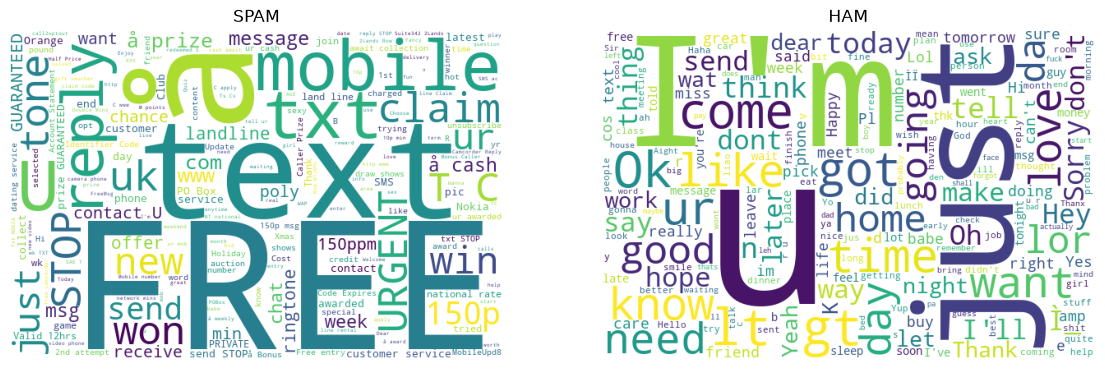

In [6]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab in zip(axes, ["spam", "ham"]):
    text = " ".join(df[df["label"] == lab]["text"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   stopwords=ENGLISH_STOP_WORDS).generate(text)
    ax.imshow(wc)
    ax.set_title(lab.upper())
    ax.axis("off")
plt.show()

In [7]:
import re

def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " urltoken ", t)   # links
    t = re.sub(r"\d+", " numtoken ", t)                # phone numbers, prices
    t = re.sub(r"[^a-z£$\s]", " ", t)                  # remove other symbols
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].apply(clean_text)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

df[["text", "clean"]].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in numtoken a wkly comp to win fa c...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"],
    test_size=0.2, stratify=df["target"], random_state=42)

print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
print("Spam share in train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: 4135 | Test: 1034
Spam share in train: 0.126 | test: 0.127


              precision    recall  f1-score   support

         ham       0.99      0.97      0.98       903
        spam       0.84      0.95      0.89       131

    accuracy                           0.97      1034
   macro avg       0.92      0.96      0.94      1034
weighted avg       0.97      0.97      0.97      1034



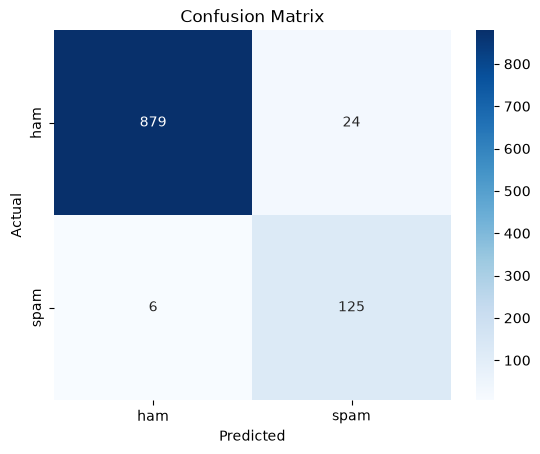

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

In [10]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

def make_tfidf():
    return TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}

rows = []
fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision (spam)": precision_score(y_test, p),
        "Recall (spam)": recall_score(y_test, p),
        "F1 (spam)": f1_score(y_test, p),
    })

results = pd.DataFrame(rows).round(3).sort_values("F1 (spam)", ascending=False)
results

,Model,Accuracy,Precision (spam),Recall (spam),F1 (spam)
3,Random Forest,0.981,0.951,0.893,0.921
2,Linear SVM,0.980,0.923,0.916,0.920
1,Naive Bayes,0.977,1.000,0.817,0.899
0,Logistic Regression,0.971,0.839,0.954,0.893


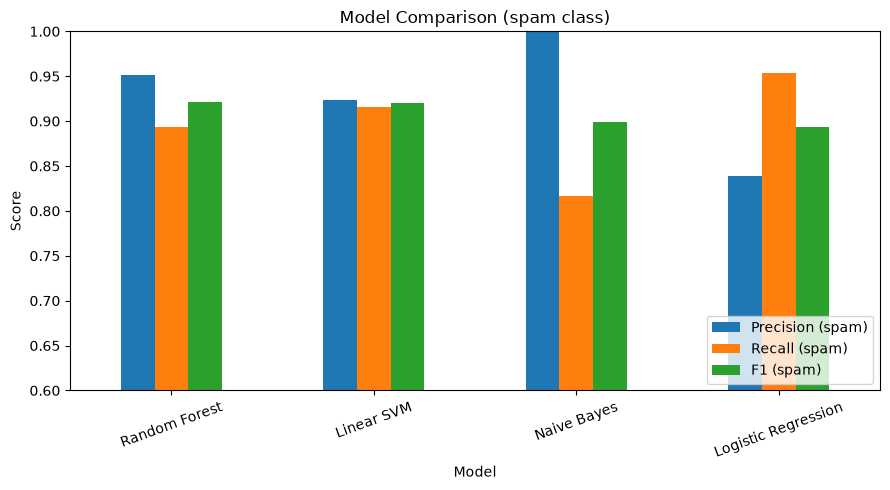

In [11]:
results.set_index("Model")[["Precision (spam)", "Recall (spam)", "F1 (spam)"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0.6, 1.0))
plt.title("Model Comparison (spam class)")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
import joblib

best_name = results.iloc[0]["Model"]
print("Best model:", best_name)

best = fitted[best_name]
joblib.dump(best, "../model.joblib")

Best model: Random Forest


['../model.joblib']

In [13]:
best = fitted[best_name]
pred = best.predict(X_test)

errors = pd.DataFrame({
    "text": df.loc[X_test.index, "text"],
    "actual": y_test.map({0: "ham", 1: "spam"}),
    "predicted": pd.Series(pred, index=X_test.index).map({0: "ham", 1: "spam"}),
})
errors = errors[errors["actual"] != errors["predicted"]]

false_pos = errors[errors["actual"] == "ham"]
false_neg = errors[errors["actual"] == "spam"]

print("Model:", best_name)
print("Total mistakes:", len(errors))
print("False positives (ham flagged as spam):", len(false_pos))
print("False negatives (spam missed):", len(false_neg))

Model: Random Forest
Total mistakes: 20
False positives (ham flagged as spam): 6
False negatives (spam missed): 14


In [14]:
pd.set_option("display.max_colwidth", 200)

print("=== HAM FLAGGED AS SPAM ===")
display(false_pos[["text"]].head(10))

print("=== SPAM THAT WAS MISSED ===")
display(false_neg[["text"]].head(10))

=== HAM FLAGGED AS SPAM ===


,text
1952,No got new job at bar in airport on satsgettin 4.47per hour but means no lie in! keep in touch
2888,Your bill at 3 is å£33.65 so thats not bad!
2491,"\Im at arestaurant eating squid! i will be out about 10:30 wanna dosomething or is that to late?\"""""
3586,Yep then is fine 7.30 or 8.30 for ice age.
1448,I'm always on yahoo messenger now. Just send the message to me and i.ll get it you may have to send it in the mobile mode sha but i.ll get it. And will reply.
2339,Rightio. 11.48 it is then. Well arent we all up bright and early this morning.


=== SPAM THAT WAS MISSED ===


,text
520,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750
2800,We currently have a message awaiting your collection. To collect your message just call 08718723815.
1422,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Callså£1/minMobsmoreLKPOBOX177HP51FL
3947,Missed call alert. These numbers called but left no message. 07008009200
660,SMS. ac sun0819 posts HELLO:\You seem cool
2302,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)
4497,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
3888,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)"
3330,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!"
5062,"Latest News! Police station toilet stolen, cops have nothing to go on!"


In [15]:
lr = fitted["Logistic Regression"]
vec = lr.named_steps["tfidf"]
coefs = lr.named_steps["clf"].coef_[0]
words = vec.get_feature_names_out()

top = pd.DataFrame({"word": words, "weight": coefs}).sort_values("weight", ascending=False)

print("Words that push toward SPAM:")
display(top.head(15))
print("Words that push toward HAM:")
display(top.tail(15))

Words that push toward SPAM:


,word,weight
3045,numtoken,10.246242
5076,urltoken,4.937535
2787,mobile,3.566278
4679,text,3.459050
3958,reply,3.443827
1434,free,3.104118
4951,txt,2.505565
4488,stop,2.279529
2966,new,2.257130
4204,service,2.160948


Words that push toward HAM:


,word,weight
2254,know,-0.964078
5217,want,-0.999042
5404,work,-1.000351
5247,wat,-1.050171
2439,ll,-1.064611
693,come,-1.077583
879,da,-1.107820
1860,hey,-1.129223
2584,lt gt,-1.159588
1706,gt,-1.269028
